In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import seaborn as sns
import datetime    
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

In [2]:
from scipy.stats import ttest_ind

In [3]:
data = pd.read_csv(filepath_or_buffer= r"D:\Code Practice\Simplilearn\02 IHFC AIML Applied Data Science with Python\Project 2\marketing_data.csv")

In [4]:
pd.set_option("display.max_columns", None)
data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,"$84,835.00",0,0,6/16/14,0,189,104,379,111,189,218,1,4,4,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,"$57,091.00",0,0,6/15/14,0,464,5,64,7,0,37,1,7,3,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,"$67,267.00",0,1,5/13/14,0,134,11,59,15,2,30,1,3,2,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,"$32,474.00",1,1,5/11/14,0,10,0,1,0,0,0,1,1,0,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,"$21,474.00",1,0,4/8/14,0,6,16,24,11,0,34,2,3,1,2,7,1,0,0,0,0,1,0,SP


In [5]:
data.rename(columns=lambda x: x.strip(), inplace=True)

In [6]:
data["Income"] = data["Income"].str.replace('$', '').str.replace(',', '').astype(float)

In [7]:
data["Total_Children"] = data["Kidhome"] + data["Teenhome"]

In [8]:
data["Income"] = data.groupby(["Education","Marital_Status"])[["Income"]].transform(lambda x: x.fillna(x.median()))

In [9]:
data["Total_Spent"] = data["MntWines"] + data["MntFruits"] + \
      data["MntMeatProducts"] + data["MntFishProducts"] + \
          data["MntSweetProducts"] + data["MntGoldProds"]

In [10]:
one_hot = OneHotEncoder()

In [11]:
data["Marital_Status_Encoded"] = one_hot.fit_transform(data[["Marital_Status"]]).toarray().argmax(axis=1)   

In [12]:
data[["Marital_Status_Encoded"]]

,Marital_Status_Encoded
0,2
1,4
2,3
3,5
4,4
...,...
2235,2
2236,3
2237,2
2238,3


In [13]:
data["Education"].unique()

<StringArray>
['Graduation', 'PhD', '2n Cycle', 'Master', 'Basic']
Length: 5, dtype: str

In [14]:
data["Age"] = 2026 - data["Year_Birth"]

In [15]:
older_customers = data[data["Age"] > data["Age"].median()]
younger_customers = data[data["Age"] <= data["Age"].median()]

In [16]:
t_stat, p_value = ttest_ind(older_customers["NumStorePurchases"], younger_customers["NumStorePurchases"])

In [17]:
print("Hypothesis Test Results:")
print(f"T-statistic the t value: {t_stat}")
print(f"P-value: {p_value}")

Hypothesis Test Results:
T-statistic the t value: 6.334764651957808
P-value: 2.8645585610831485e-10


In [18]:
data["Online_Purchases"] = data["NumWebPurchases"] + data["NumCatalogPurchases"]

In [19]:
with_children = data[data["Total_Children"] > 0]
without_children = data[data["Total_Children"] == 0]

In [20]:
t_stat, p_value = ttest_ind(with_children["Online_Purchases"], without_children["Online_Purchases"])    
print("Hypothesis Test Results for Online Purchases:")
print(f"T-statistic the t value: {t_stat}") 
print(f"P-value: {p_value}")

Hypothesis Test Results for Online Purchases:
T-statistic the t value: -16.016599075664665
P-value: 9.593352232105633e-55


In [21]:
store_sale = data["NumStorePurchases"]
alt_channel_sale = data["Online_Purchases"] 
correlation = np.corrcoef(store_sale, alt_channel_sale)[0, 1]
print(f"Correlation between Store Purchases and Online Purchases: {correlation}")

Correlation between Store Purchases and Online Purchases: 0.6153592978630221


In [22]:
data['Total_Purchase'] = data['NumWebPurchases'] + data['NumCatalogPurchases'] + data['NumStorePurchases']

In [23]:
us_customers = data[data["Country"] == "US"]
non_us_customers = data[data["Country"] != "US"]

In [24]:
t_stat, p_value = ttest_ind(us_customers["Total_Purchase"], non_us_customers["Total_Purchase"])

In [25]:
print("Hypothesis Test Results:")
print(f"T-statistic: {t_stat}")
print(f"P-value: {p_value}")

Hypothesis Test Results:
T-statistic: 1.4512386847675383
P-value: 0.14685355981832415


In [26]:
product_categories = data[['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']]
product_categories.columns

Index(['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
       'MntSweetProducts', 'MntGoldProds'],
      dtype='str')

In [27]:
product_categories.sum().sort_values(ascending=False)

MntWines            680816
MntMeatProducts     373968
MntGoldProds         98609
MntFishProducts      84057
MntSweetProducts     60621
MntFruits            58917
dtype: int64

In [28]:
top_product = product_categories.sum().idxmax()
lowest_product = product_categories.sum().idxmin()

In [29]:
top_product

'MntWines'

In [30]:
lowest_product

'MntFruits'

<Axes: title={'center': 'Total Sales by Product Category'}>

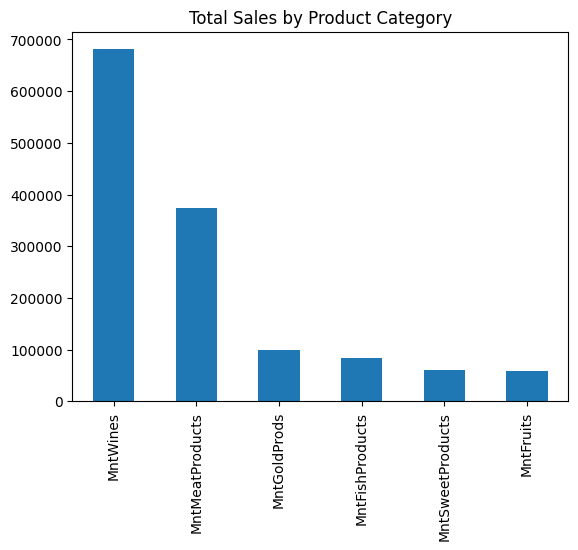

In [31]:
product_categories.sum().sort_values(ascending=False).plot(kind='bar', title='Total Sales by Product Category')

In [32]:
data[["Age","AcceptedCmp5"]].corr()

,Age,AcceptedCmp5
Age,1.000000,-0.007123
AcceptedCmp5,-0.007123,1.000000


In [33]:
pd.DataFrame(data.groupby("Country")["AcceptedCmp5"].sum()).sort_values(by="AcceptedCmp5", ascending=False)

,AcceptedCmp5
Country,
SP,89
CA,21
SA,21
AUS,13
GER,8
IND,6
US,5
ME,0


In [34]:
data[["Total_Children","Total_Spent"]].corr()

,Total_Children,Total_Spent
Total_Children,1.000000,-0.498888
Total_Spent,-0.498888,1.000000


In [35]:
data.groupby("Education")["Complain"].sum().sort_values(ascending=False)

Education
Graduation    14
2n Cycle       4
Master         2
PhD            1
Basic          0
Name: Complain, dtype: int64